# TP #2 — Régression logistique
**Apprentissage Automatique Avancé** — Prof. Abdelouahab Moussaoui

Contenu du notebook (tout en Python) :
- **Partie I, Exercice 1** : modèle logistique simple CHD ~ AGE (`MCV.txt`) — le sujet l'indique en R, la version Python (`statsmodels`) est fournie ici, avec en fin de partie l'équivalent R.
- **Partie II, Exercice 2** : régression logistique sur les chiffres (`load_digits`).
- **Partie III, Mini-projet** : filtrage de spams (jeu *spambase*).

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats

np.set_printoptions(precision=4, suppress=True)
pd.set_option('display.precision', 4)

---
# Partie I — Exercice 1 : modèle logistique simple (CHD en fonction de l'âge)
100 individus : `AGE`, présence (1) / absence (0) d'une maladie cardiovasculaire `CHD`, numéro `ID` et classe d'âge `AGRP`.

## Question 1 — Charger et afficher les données regroupées en classes d'âge

In [2]:
mcv = pd.read_csv('MCV.txt', sep=r'\s+')
print(mcv.shape)
display(mcv.head(10))

# Données regroupées par classe d'âge
groupes = mcv.groupby('AGRP').agg(effectif=('CHD', 'size'),
                                  age_min=('AGE', 'min'),
                                  age_max=('AGE', 'max'),
                                  malades=('CHD', 'sum'),
                                  proportion=('CHD', 'mean'))
display(groupes)

(100, 4)


,ID,AGRP,AGE,CHD
0,1,1,20,0
1,2,1,23,0
2,3,1,24,0
3,4,1,25,0
4,5,1,25,1
5,6,1,26,0
6,7,1,26,0
7,8,1,28,0
8,9,1,28,0
9,10,1,29,0


,effectif,age_min,age_max,malades,proportion
AGRP,,,,,
1,10,20,29,1,0.1000
2,15,30,34,2,0.1333
3,12,35,39,3,0.2500
4,15,40,44,5,0.3333
5,13,45,49,6,0.4615
6,8,50,54,5,0.6250
7,17,55,59,13,0.7647
8,10,60,69,8,0.8000


## Question 2 — Nuage de points CHD vs AGE

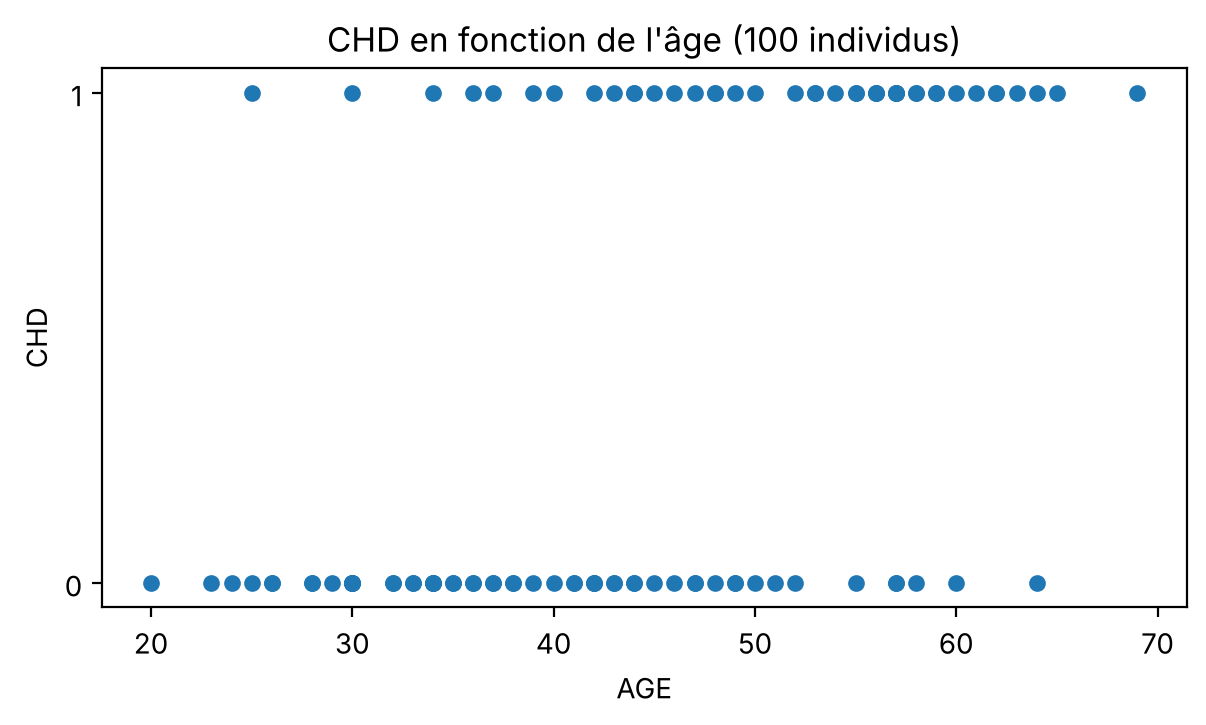

In [3]:
plt.figure(figsize=(7, 3.5))
plt.scatter(mcv.AGE, mcv.CHD, s=25)
plt.yticks([0, 1])
plt.xlabel("AGE"); plt.ylabel("CHD")
plt.title("CHD en fonction de l'âge (100 individus)")
plt.show()

**Commentaire.** La variable réponse ne prend que deux valeurs, les points s'alignent donc sur deux droites horizontales (CHD = 0 et CHD = 1). On voit que les CHD = 1 sont **rares avant 40 ans et de plus en plus fréquents après 50 ans**, mais ce nuage est difficile à lire : les points se superposent et on ne distingue ni la forme de la relation ni son intensité. Il faut regrouper les données pour mieux voir.

## Question 3 — Proportion de malades par classe d'âge

,centre,p
1,24.5,0.1000
2,32.0,0.1333
3,37.0,0.2500
4,42.0,0.3333
5,47.0,0.4615
6,52.0,0.6250
7,57.0,0.7647
8,64.5,0.8000


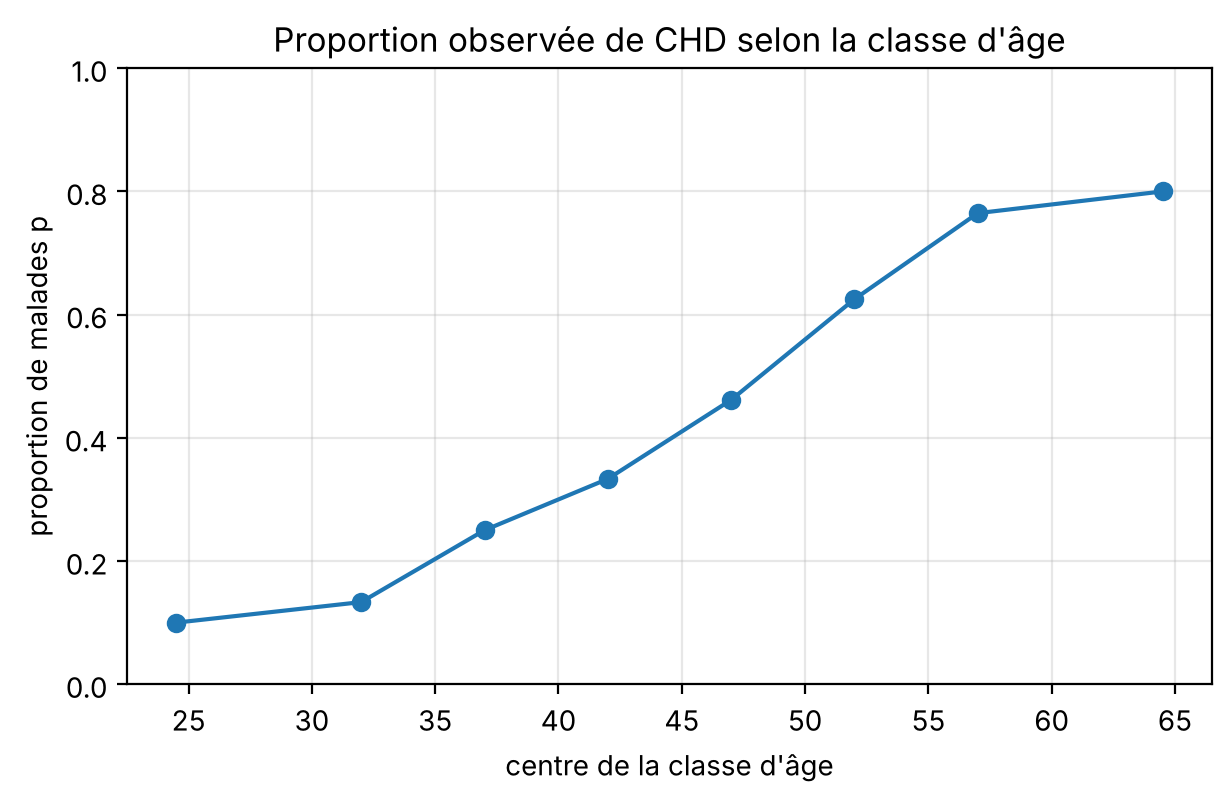

In [4]:
# Centres des classes d'âge : 20-29, 30-34, 35-39, 40-44, 45-49, 50-54, 55-59, 60-69
centre = np.array([24.5, 32, 37, 42, 47, 52, 57, 64.5])
p = mcv.groupby('AGRP').CHD.mean().values

tab = pd.DataFrame({'centre': centre, 'p': p}, index=range(1, 9))
display(tab)

plt.figure(figsize=(7, 4))
plt.plot(centre, p, 'o-')
plt.xlabel("centre de la classe d'âge"); plt.ylabel("proportion de malades p")
plt.title("Proportion observée de CHD selon la classe d'âge")
plt.ylim(0, 1); plt.grid(alpha=.3)
plt.show()

**Commentaire.**
- **Il y a bien une liaison entre CHD et AGE** : la proportion de malades passe de **10 %** (20–29 ans) à **80 %** (60–69 ans), de façon monotone croissante.
- **Forme du graphique :** une courbe en **« S » (sigmoïde)** : croissance lente aux âges jeunes, plus rapide au milieu (autour de 45–55 ans), puis aplatissement vers 1.
- **Intérêt par rapport au nuage précédent :** le regroupement fait apparaître la tendance et sa forme, ce que le nuage de 0/1 ne permettait pas.
- **Modèle suggéré :** un modèle **linéaire** n'est pas adapté (il pourrait prédire des probabilités < 0 ou > 1 et la relation n'est pas linéaire). On utilise un modèle **logistique** (ou probit) : $\text{logit}(p)=\ln\frac{p}{1-p}=\beta_0+\beta_1\,\text{AGE}$.

## Question 4 — Régression logistique de CHD en fonction de AGE

In [5]:
X = sm.add_constant(mcv[['AGE']])
logit = sm.GLM(mcv.CHD, X, family=sm.families.Binomial()).fit()
print(logit.summary())

lr_stat = logit.null_deviance - logit.deviance
ddl = int(logit.df_model)
print(f"\nDéviance nulle      : {logit.null_deviance:.3f} sur {int(logit.df_resid + ddl)} ddl")
print(f"Déviance résiduelle : {logit.deviance:.3f} sur {int(logit.df_resid)} ddl")
print(f"Test du rapport de vraisemblance : chi2 = {lr_stat:.3f}, ddl = {ddl}, p-value = {stats.chi2.sf(lr_stat, ddl):.2e}")

                 Generalized Linear Model Regression Results                  
Dep. Variable:                    CHD   No. Observations:                  100
Model:                            GLM   Df Residuals:                       98
Model Family:                Binomial   Df Model:                            1
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -53.677
Date:                Mon, 09 Nov 2026   Deviance:                       107.35
Time:                        11:21:17   Pearson chi2:                     102.
No. Iterations:                     4   Pseudo R-squ. (CS):             0.2541
Covariance Type:            nonrobust                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -5.3095      1.134     -4.683      0.0

**Commentaire.**
- **Modèle ajusté :** $\text{logit}(\hat p) = -5{,}31 + 0{,}111\times\text{AGE}$.
- **Significativité (test de Wald) :** le coefficient de AGE est significatif (z ≈ 4,61, p < 0,001) ; l'intercept l'est aussi (z ≈ −4,68). L'âge influence donc significativement la probabilité de CHD.
- **Test global (rapport de vraisemblance) :** la déviance passe de 136,66 (modèle nul, 99 ddl) à 107,35 (modèle avec AGE, **98 ddl résiduels** = 100 observations − 2 paramètres). La baisse de 29,3 pour 1 ddl est très significative (p ≈ 6×10⁻⁸) : le modèle avec AGE est nettement meilleur que le modèle constant.
- **Signe positif :** la probabilité de maladie croît avec l'âge.

## Question 5 — Proportions observées et courbe logistique ajustée

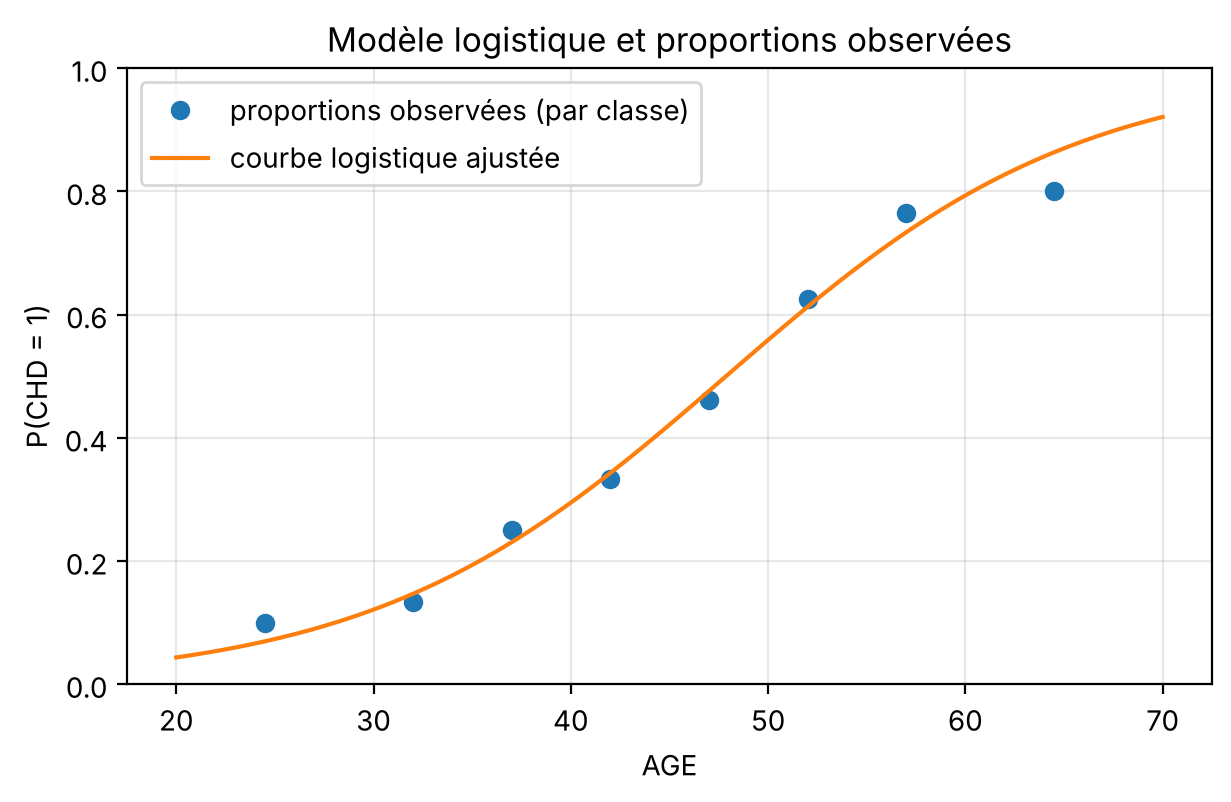

In [6]:
ages = np.linspace(20, 70, 200)
p_logit = logit.predict(sm.add_constant(pd.DataFrame({'AGE': ages})))

plt.figure(figsize=(7, 4))
plt.plot(centre, p, 'o', label="proportions observées (par classe)")
plt.plot(ages, p_logit, '-', label="courbe logistique ajustée")
plt.xlabel("AGE"); plt.ylabel("P(CHD = 1)")
plt.ylim(0, 1); plt.grid(alpha=.3); plt.legend()
plt.title("Modèle logistique et proportions observées")
plt.show()

**Commentaire.** La courbe ajustée suit de près les proportions observées par classe d'âge, y compris la forme en S : le modèle logistique décrit correctement la relation. Les petits écarts sont raisonnables vu les effectifs des classes (8 à 17 individus), donc des proportions assez bruitées.

## Question 6 — Modèle probit et comparaison

                 Generalized Linear Model Regression Results                  
Dep. Variable:                    CHD   No. Observations:                  100
Model:                            GLM   Df Residuals:                       98
Model Family:                Binomial   Df Model:                            1
Link Function:                 Probit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -53.749
Date:                Mon, 09 Nov 2026   Deviance:                       107.50
Time:                        11:21:17   Pearson chi2:                     102.
No. Iterations:                     4   Pseudo R-squ. (CS):             0.2530
Covariance Type:            nonrobust                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -3.1457      0.625     -5.036      0.0

,logit,probit
intercept,-5.3095,-3.1457
coef AGE,0.1109,0.0658
log-vraisemblance,-53.6765,-53.7494
déviance résiduelle,107.3531,107.4988
AIC,111.3531,111.4988


Rapport des coefficients logit/probit (AGE)      : 1.686
Rapport des coefficients logit/probit (intercept): 1.688


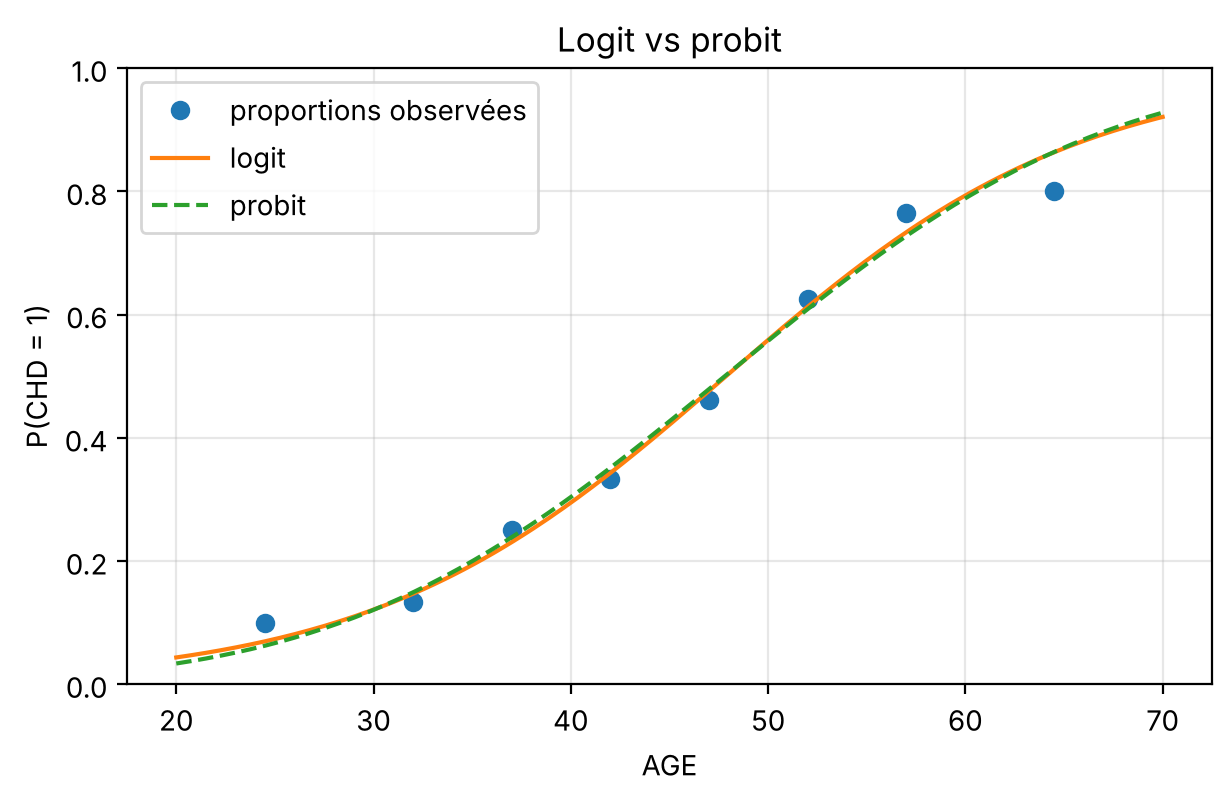

Écart maximal entre les deux probabilités ajustées : 0.0098271241813414


In [7]:
probit = sm.GLM(mcv.CHD, X, family=sm.families.Binomial(sm.families.links.Probit())).fit()
print(probit.summary())

comp = pd.DataFrame({
    'logit':  [logit.params['const'],  logit.params['AGE'],  logit.llf,  logit.deviance,  logit.aic],
    'probit': [probit.params['const'], probit.params['AGE'], probit.llf, probit.deviance, probit.aic]},
    index=['intercept', 'coef AGE', 'log-vraisemblance', 'déviance résiduelle', 'AIC'])
display(comp)
print("Rapport des coefficients logit/probit (AGE)      :", round(logit.params['AGE'] / probit.params['AGE'], 3))
print("Rapport des coefficients logit/probit (intercept):", round(logit.params['const'] / probit.params['const'], 3))

p_probit = probit.predict(sm.add_constant(pd.DataFrame({'AGE': ages})))
plt.figure(figsize=(7, 4))
plt.plot(centre, p, 'o', label="proportions observées")
plt.plot(ages, p_logit, '-', label="logit")
plt.plot(ages, p_probit, '--', label="probit")
plt.xlabel("AGE"); plt.ylabel("P(CHD = 1)"); plt.ylim(0, 1)
plt.grid(alpha=.3); plt.legend(); plt.title("Logit vs probit")
plt.show()
print("Écart maximal entre les deux probabilités ajustées :", float(np.max(np.abs(p_logit - p_probit))))

**Commentaire.**
- Dans le probit, AGE est aussi très significatif (z ≈ 4,93).
- Les **coefficients ne sont pas comparables directement** : ils sont sur des échelles différentes (la loi logistique a un écart-type ≈ 1,81 contre 1 pour la loi normale). On observe un rapport logit/probit d'environ **1,7**, ordre de grandeur habituel.
- **Qualité d'ajustement quasi identique** : déviances 107,35 (logit) et 107,50 (probit), AIC 111,35 et 111,50. Les deux courbes sont presque superposées sur le graphique : l'écart maximal entre probabilités ajustées est de l'ordre de un point de pourcentage.
- **Conclusion :** les deux modèles sont équivalents ici. On préfère en pratique le **logit** pour l'interprétation directe en termes de **cotes (odds) et d'odds ratios**, que le probit n'offre pas.

## Question 7 — Cote d'un individu de 30 ans et rapport de cotes

In [8]:
def cote(p):            # odds = p / (1 - p)
    return p / (1 - p)

nouveau = sm.add_constant(pd.DataFrame({'AGE': [30.0]}), has_constant='add')
p30_logit  = float(logit.predict(nouveau)[0])
p30_probit = float(probit.predict(nouveau)[0])

print(f"LOGIT  : p(30 ans) = {p30_logit:.4f}  -> cote = {cote(p30_logit):.4f}  (= exp(b0 + 30 b1))")
print(f"PROBIT : p(30 ans) = {p30_probit:.4f}  -> cote = {cote(p30_probit):.4f}")

# Rapport de cotes (odds ratio) pour +1 an d'âge
b1 = logit.params['AGE']
ic = np.exp(logit.conf_int().loc['AGE'].values)
print(f"\nLOGIT : OR(+1 an) = exp(b1) = {np.exp(b1):.4f}   IC 95 % = [{ic[0]:.4f} ; {ic[1]:.4f}]")
print(f"        OR(+10 ans) = exp(10 b1) = {np.exp(10*b1):.3f}")

# Dans le probit, le rapport de cotes n'est pas constant : il dépend de l'âge
print("\nPROBIT : rapport de cotes entre a+1 et a ans (non constant)")
for a in (30, 40, 50, 60):
    pa  = float(probit.predict(sm.add_constant(pd.DataFrame({'AGE': [float(a)]}), has_constant='add'))[0])
    pa1 = float(probit.predict(sm.add_constant(pd.DataFrame({'AGE': [float(a + 1)]}), has_constant='add'))[0])
    print(f"   age {a} -> {a+1} : OR = {cote(pa1)/cote(pa):.4f}")

LOGIT  : p(30 ans) = 0.1211  -> cote = 0.1378  (= exp(b0 + 30 b1))
PROBIT : p(30 ans) = 0.1207  -> cote = 0.1372

LOGIT : OR(+1 an) = exp(b1) = 1.1173   IC 95 % = [1.0658 ; 1.1713]
        OR(+10 ans) = exp(10 b1) = 3.032

PROBIT : rapport de cotes entre a+1 et a ans (non constant)
   age 30 -> 31 : OR = 1.1314
   age 40 -> 41 : OR = 1.1144
   age 50 -> 51 : OR = 1.1112
   age 60 -> 61 : OR = 1.1219


**Commentaire.**
- **Cote à 30 ans :** les deux modèles donnent pratiquement le même résultat : probabilité ≈ 0,12 et **cote ≈ 0,14** (soit environ 1 chance de maladie contre 7 d'absence).
- **Rapport de cotes pour la variable AGE (logit) :** $\widehat{OR}=e^{\hat\beta_1}\approx 1{,}117$ (IC 95 % ≈ [1,066 ; 1,171]) : **chaque année d'âge supplémentaire multiplie la cote de maladie par 1,117 (+11,7 %)**, soit un facteur ≈ 3,0 pour 10 ans. Ce rapport est **constant** dans le modèle logit.
- Dans le **probit**, il n'existe pas de rapport de cotes constant : il varie (légèrement) avec l'âge : ≈ 1,11 à 1,13 entre 30 et 60 ans (calcul ci-dessus). C'est une raison de plus de privilégier le logit.

**Équivalent en R** (non exécuté ici, fourni pour référence puisque la Partie I du sujet est en R) :
```r
mcv <- read.table("MCV.txt", header = TRUE)
plot(mcv$AGE, mcv$CHD)
centre <- c(24.5, 32, 37, 42, 47, 52, 57, 64.5)
p <- tapply(mcv$CHD, mcv$AGRP, mean)
plot(centre, p)
logit  <- glm(CHD ~ AGE, family = binomial(link = "logit"),  data = mcv); summary(logit)
probit <- glm(CHD ~ AGE, family = binomial(link = "probit"), data = mcv); summary(probit)
predict(logit, data.frame(AGE = 30), type = "response")
exp(coef(logit)["AGE"])
```

---
# Partie II — Exercice 2 : régression logistique des chiffres
> **Remarque :** le sujet illustre avec MNIST (28×28) mais demande `load_digits()` de scikit-learn : ce jeu contient **1797 images de 8×8 pixels** (64 variables, niveaux de gris de 0 à 16), classes 0 à 9.

## Questions 1 et 2 — Chargement et affichage des images avec leurs étiquettes

images : (1797, 8, 8) | données aplaties : (1797, 64) | étiquettes : (1797,)


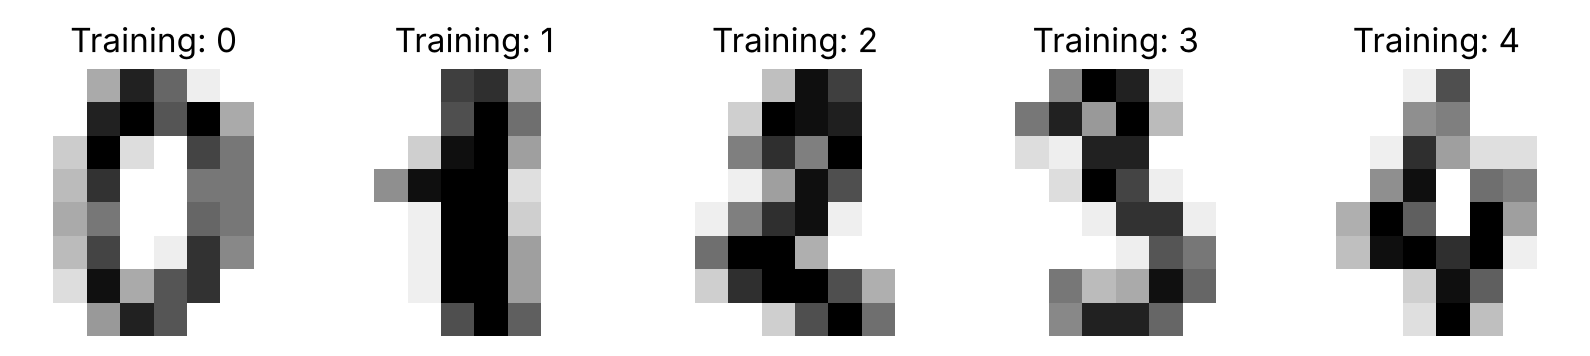

In [9]:
from sklearn.datasets import load_digits
digits = load_digits()

print("images :", digits.images.shape, "| données aplaties :", digits.data.shape, "| étiquettes :", digits.target.shape)

plt.figure(figsize=(10, 2.4))
for i, (image, label) in enumerate(zip(digits.images[:5], digits.target[:5])):
    plt.subplot(1, 5, i + 1)
    plt.imshow(image, cmap=plt.cm.gray_r)
    plt.axis('off')
    plt.title(f"Training: {label}")
plt.show()

## Question 3 — Séparation entraînement / test

In [10]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(
    digits.data, digits.target, test_size=0.25, random_state=0)
print("train :", x_train.shape, y_train.shape)
print("test  :", x_test.shape, y_test.shape)

train : (1347, 64) (1347,)
test  : (450, 64) (450,)


## Question 4 — Création du modèle (4 étapes)

In [11]:
# Étape 1 : importer le modèle
from sklearn.linear_model import LogisticRegression

# Étape 2 : créer une instance du modèle (max_iter élevé pour assurer la convergence)
logisticRegr = LogisticRegression(max_iter=10000)

# Étape 3 : entraîner le modèle sur les données (il mémorise ce qu'il a appris)
logisticRegr.fit(x_train, y_train)

# Étape 4 : prédire les étiquettes de nouvelles données (nouvelles images)
print("Prédiction pour la 1re image de test :", logisticRegr.predict(x_test[0].reshape(1, -1)), "| vraie classe :", y_test[0])
predictions = logisticRegr.predict(x_test)
print("Prédictions pour les 10 premières images de test :", predictions[:10])
print("Vraies classes                                   :", y_test[:10])

Prédiction pour la 1re image de test : [2] | vraie classe : 2
Prédictions pour les 10 premières images de test : [2 8 2 6 6 7 1 9 8 5]
Vraies classes                                   : [2 8 2 6 6 7 1 9 8 5]


## Question 5 — Performance du modèle

In [12]:
score_test  = logisticRegr.score(x_test, y_test)
score_train = logisticRegr.score(x_train, y_train)
print(f"Précision (accuracy) sur le jeu de test         : {score_test:.4f}")
print(f"Précision (accuracy) sur le jeu d'entraînement  : {score_train:.4f}")

Précision (accuracy) sur le jeu de test         : 0.9533
Précision (accuracy) sur le jeu d'entraînement  : 1.0000


**Commentaire.** Le modèle classe correctement environ **95 %** des images de test. Il atteint 100 % sur l'entraînement : un petit écart train/test qui indique un léger **surapprentissage** (64 variables, modèle multinomial flexible), sans conséquence grave ici. La précision globale est élevée pour un modèle linéaire.

## Question 6 — Matrice de confusion

[[37  0  0  0  0  0  0  0  0  0]
 [ 0 40  0  0  0  0  0  0  2  1]
 [ 0  0 41  3  0  0  0  0  0  0]
 [ 0  0  0 43  0  0  0  0  1  1]
 [ 0  0  0  0 37  0  0  1  0  0]
 [ 0  0  0  0  0 46  0  0  0  2]
 [ 0  1  0  0  0  0 51  0  0  0]
 [ 0  0  0  1  1  0  0 46  0  0]
 [ 0  3  1  0  0  0  0  0 43  1]
 [ 0  0  0  0  0  1  0  0  1 45]]


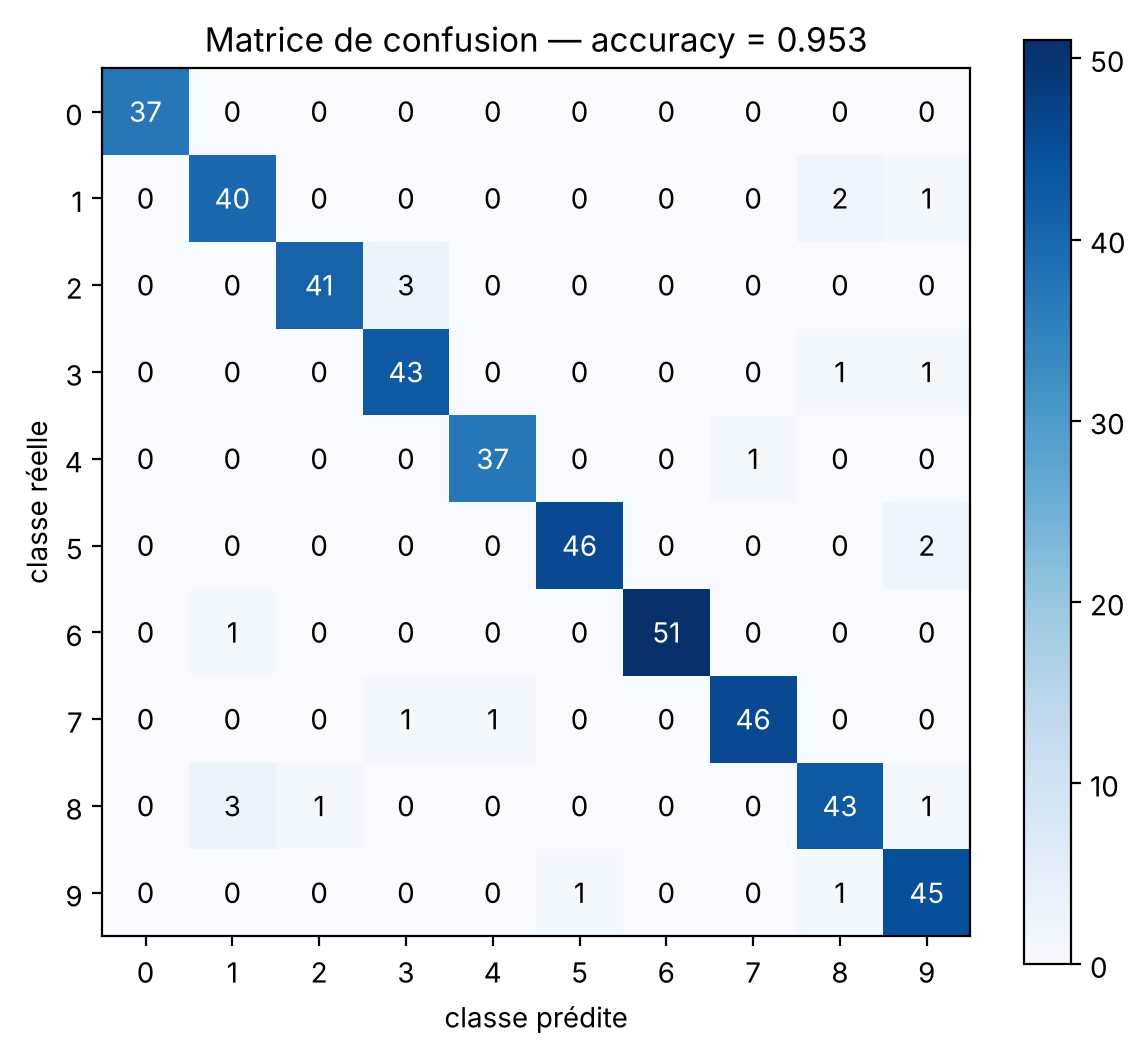

              precision    recall  f1-score   support

           0      1.000     1.000     1.000        37
           1      0.909     0.930     0.920        43
           2      0.976     0.932     0.953        44
           3      0.915     0.956     0.935        45
           4      0.974     0.974     0.974        38
           5      0.979     0.958     0.968        48
           6      1.000     0.981     0.990        52
           7      0.979     0.958     0.968        48
           8      0.915     0.896     0.905        48
           9      0.900     0.957     0.928        47

    accuracy                          0.953       450
   macro avg      0.955     0.954     0.954       450
weighted avg      0.954     0.953     0.954       450

Confusions les plus fréquentes (réel -> prédit : nombre) : [('2->3', 3), ('8->1', 3), ('1->8', 2), ('5->9', 2), ('1->9', 1)]


In [13]:
from sklearn.metrics import confusion_matrix, classification_report
cm = confusion_matrix(y_test, predictions)
print(cm)

plt.figure(figsize=(7, 6))
plt.imshow(cm, cmap='Blues')
plt.colorbar()
plt.xticks(range(10)); plt.yticks(range(10))
plt.xlabel("classe prédite"); plt.ylabel("classe réelle")
plt.title(f"Matrice de confusion — accuracy = {score_test:.3f}")
for i in range(10):
    for j in range(10):
        plt.text(j, i, cm[i, j], ha='center', va='center',
                 color='white' if cm[i, j] > cm.max() / 2 else 'black')
plt.show()

print(classification_report(y_test, predictions, digits=3))

# Erreurs les plus fréquentes (hors diagonale)
hors_diag = cm.copy(); np.fill_diagonal(hors_diag, 0)
couples = [(i, j, hors_diag[i, j]) for i in range(10) for j in range(10) if hors_diag[i, j] > 0]
couples.sort(key=lambda t: -t[2])
print("Confusions les plus fréquentes (réel -> prédit : nombre) :", [(f"{i}->{j}", int(n)) for i, j, n in couples[:5]])

**Explication.** Chaque ligne correspond à la **vraie classe**, chaque colonne à la **classe prédite** ; la diagonale compte les images bien classées et les valeurs hors diagonale les erreurs. Ici la diagonale domine très largement : 429 images sur 450 sont bien classées (**21 erreurs**).

Les erreurs sont dispersées et portent sur des chiffres de forme proche : **2 prédit 3** (3 fois), **8 prédit 1** (3 fois), 5 prédit 9, 1 prédit 8… Le chiffre **0** est parfaitement reconnu et le **8** est le moins bien reconnu (rappel ≈ 0,90).

---
# Partie III — Mini-projet : filtrage de spams (*spambase*)
4601 messages (≈ 39 % de spams) décrits par 57 variables : fréquences de mots (48, `word_freq_*`), fréquences de caractères spéciaux (6, `char_freq_*`) et statistiques sur les séquences de majuscules (3, `capital_run_length_*`).

> **Fichier requis :** `spambase.csv` (jeu UCI avec en-têtes ; la dernière colonne `spam` vaut 1 pour un spam), à placer **dans le même dossier que le notebook**.

## Chargement des données

In [14]:
SPAM = pd.read_csv('spambase.csv') if os.path.exists('spambase.csv') else None
if SPAM is None:
    print(">>> spambase.csv introuvable : placez-le à côté du notebook puis relancez (Kernel > Restart & Run All).")
else:
    print(SPAM.shape, "| valeurs manquantes :", int(SPAM.isna().sum().sum()))
    print("Répartition des classes :")
    print(SPAM.spam.value_counts().rename({0: 'ham (0)', 1: 'spam (1)'}))
    print("Taux de spams :", round(SPAM.spam.mean(), 4))
    display(SPAM.iloc[:5, list(range(3)) + [15, 48, 51, 52, 53, 54, 55, 56, 57]])

(4601, 58) | valeurs manquantes : 0
Répartition des classes :
spam
ham (0)     2788
spam (1)    1813
Name: count, dtype: int64
Taux de spams : 0.394


,word_freq_make,word_freq_address,word_freq_all,word_freq_free,char_freq_;,char_freq_!,char_freq_$,char_freq_#,capital_run_length_average,capital_run_length_longest,capital_run_length_total,spam
0,0.00,0.64,0.64,0.32,0.00,0.778,0.000,0.000,3.756,61,278,1
1,0.21,0.28,0.50,0.14,0.00,0.372,0.180,0.048,5.114,101,1028,1
2,0.06,0.00,0.71,0.06,0.01,0.276,0.184,0.010,9.821,485,2259,1
3,0.00,0.00,0.00,0.31,0.00,0.137,0.000,0.000,3.537,40,191,1
4,0.00,0.00,0.00,0.31,0.00,0.135,0.000,0.000,3.537,40,191,1


## Question 1 — Création du modèle de régression logistique

In [15]:
if SPAM is None:
    print('Section ignorée : spambase.csv introuvable (voir cellule de chargement).')
else:
    from sklearn.model_selection import train_test_split
    from sklearn.pipeline import make_pipeline
    from sklearn.preprocessing import StandardScaler
    from sklearn.linear_model import LogisticRegression

    X_spam = SPAM.drop(columns='spam')
    y_spam = SPAM['spam']

    Xa, Xt, ya, yt = train_test_split(X_spam, y_spam, test_size=0.3, random_state=0, stratify=y_spam)
    print("apprentissage :", Xa.shape, "| test :", Xt.shape)

    # Variables centrées-réduites pour que les coefficients soient comparables
    modele = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000))
    modele.fit(Xa, ya)
    print("Modèle ajusté.")

apprentissage : (3220, 57) | test : (1381, 57)
Modèle ajusté.


## Question 2 — Description et commentaire du modèle

Intercept : -2.3925

Variables qui augmentent le plus la probabilité de SPAM (coef > 0) :
capital_run_length_average    1.334
word_freq_remove              1.041
word_freq_credit              1.018
char_freq_$                   1.012
capital_run_length_longest    0.948
word_freq_000                 0.858
word_freq_3d                  0.850
word_freq_free                0.651
capital_run_length_total      0.552
char_freq_!                   0.552
dtype: float64

Variables qui diminuent le plus la probabilité de SPAM (coef < 0) :
word_freq_george       -3.636
word_freq_hp           -2.784
word_freq_cs           -1.806
word_freq_edu          -1.525
word_freq_meeting      -1.520
word_freq_project      -1.378
word_freq_lab          -0.918
word_freq_hpl          -0.898
word_freq_conference   -0.853
word_freq_85           -0.756
dtype: float64


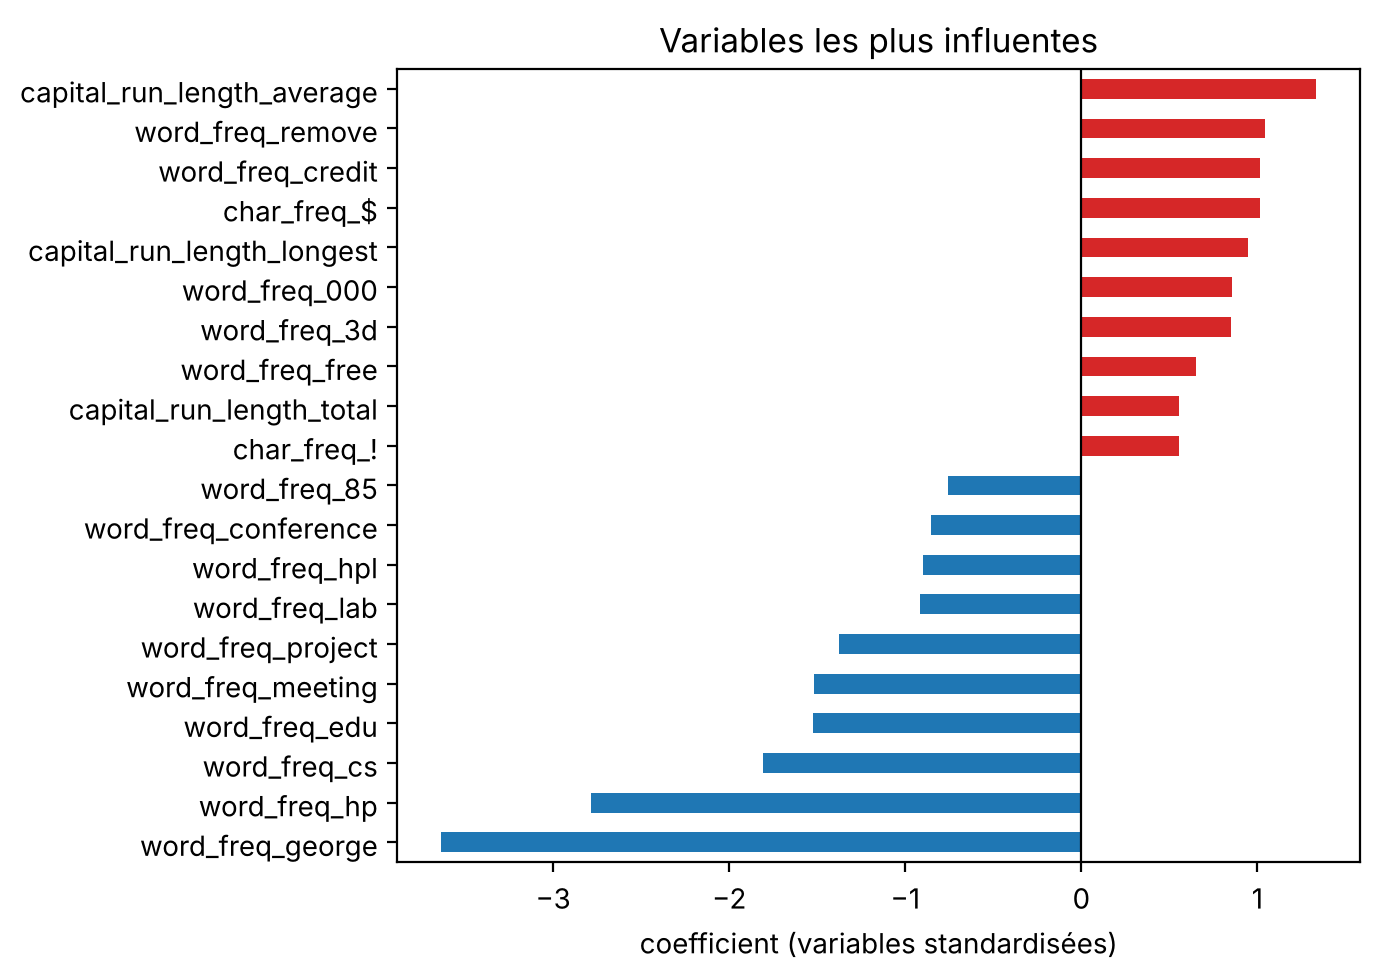


Odds ratio par écart-type (top 5 spam) :
capital_run_length_average    3.797
word_freq_remove              2.831
word_freq_credit              2.767
char_freq_$                   2.752
capital_run_length_longest    2.581
dtype: float64


In [16]:
if SPAM is None:
    print('Section ignorée : spambase.csv introuvable (voir cellule de chargement).')
else:
    lr = modele.named_steps['logisticregression']
    coef = pd.Series(lr.coef_[0], index=X_spam.columns).sort_values()
    print("Intercept :", round(float(lr.intercept_[0]), 4))
    print("\nVariables qui augmentent le plus la probabilité de SPAM (coef > 0) :")
    print(coef.tail(10).iloc[::-1].round(3))
    print("\nVariables qui diminuent le plus la probabilité de SPAM (coef < 0) :")
    print(coef.head(10).round(3))

    plt.figure(figsize=(7, 5))
    extremes = pd.concat([coef.head(10), coef.tail(10)])
    extremes.plot.barh(color=['tab:blue' if v < 0 else 'tab:red' for v in extremes])
    plt.axvline(0, c='k', lw=.8)
    plt.xlabel("coefficient (variables standardisées)")
    plt.title("Variables les plus influentes")
    plt.tight_layout(); plt.show()

    print("\nOdds ratio par écart-type (top 5 spam) :")
    print(np.exp(coef.tail(5).iloc[::-1]).round(3))

**Comment lire le modèle.** Le modèle est de la forme $\text{logit}\,P(\text{spam}) = \beta_0+\sum_j \beta_j x_j$ avec des variables **standardisées** : $\beta_j$ est la variation du log-odds pour une hausse d'un écart-type de la variable $j$, et $e^{\beta_j}$ le rapport de cotes correspondant. Un coefficient **positif** pousse vers « spam », un coefficient **négatif** vers « message légitime ». La taille du coefficient mesure l'influence relative (variables comparables car standardisées).

**Commentaire.**
- **Intercept ≈ −2,39** : pour un message dont toutes les variables sont à leur valeur moyenne, la probabilité de spam est d'environ 8 %.
- **Indices de spam** (coefficients positifs) : la **longueur moyenne des séquences de majuscules** (coef ≈ 1,33, soit un rapport de cotes ≈ 3,8 par écart-type), les mots **remove**, **credit**, **000**, **free**, **3d**, les caractères **$** et **!**, ainsi que la longueur maximale et totale des majuscules. C'est cohérent avec le spam commercial : argent, offres, urgence, texte en majuscules.
- **Indices de message légitime** (coefficients négatifs) : **george** (≈ −3,64), **hp** (≈ −2,78), **cs**, **edu**, **meeting**, **project**, **lab**, **hpl**, **conference**. Ces mots relèvent du courrier professionnel de l'auteur du jeu de données (George Forman, chez Hewlett-Packard) : ils sont très spécifiques à cette source. Le modèle en tire profit ici, mais ces variables ne se généraliseraient probablement pas à une autre boîte de messagerie.
- **Précautions :** les variables étant standardisées, les coefficients sont comparables entre eux ; mais `LogisticRegression` de scikit-learn applique par défaut une pénalité L2 (C = 1) et ne fournit pas de tests de significativité comme `summary` de R/statsmodels : on interprète donc surtout les ordres de grandeur et les signes.

## Question 3 — Validation du classifieur : taux d'erreur

Matrice de confusion (lignes = réel, colonnes = prédit ; 0 = ham, 1 = spam) :
[[790  47]
 [ 55 489]]

Taux d'erreur sur le jeu de test : 0.0739  (précision globale 0.9261)
Faux positifs (ham classé spam, le plus gênant) : 47  -> taux 0.0562
Faux négatifs (spam non détecté)                : 55  -> taux 0.1011
Taux d'erreur d'un classifieur naïf (toujours la classe majoritaire) : 0.3939
AUC : 0.9694

              precision    recall  f1-score   support

         ham      0.935     0.944     0.939       837
        spam      0.912     0.899     0.906       544

    accuracy                          0.926      1381
   macro avg      0.924     0.921     0.922      1381
weighted avg      0.926     0.926     0.926      1381



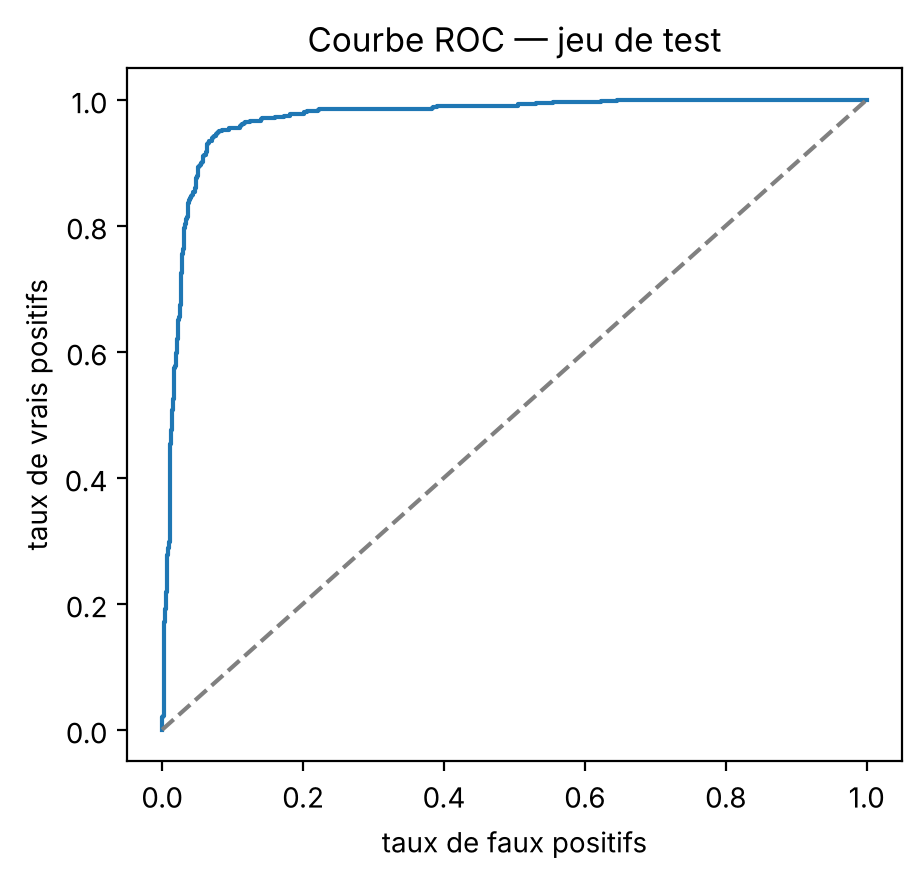

,faux positifs,faux négatifs,taux d'erreur
seuil,,,
0.5,47,55,0.0739
0.6,37,80,0.0847
0.7,28,106,0.0970
0.8,23,144,0.1209
0.9,18,212,0.1665


In [17]:
if SPAM is None:
    print('Section ignorée : spambase.csv introuvable (voir cellule de chargement).')
else:
    from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score, roc_curve

    pred = modele.predict(Xt)
    proba = modele.predict_proba(Xt)[:, 1]
    cm_spam = confusion_matrix(yt, pred)
    erreur = 1 - (pred == yt).mean()

    print("Matrice de confusion (lignes = réel, colonnes = prédit ; 0 = ham, 1 = spam) :")
    print(cm_spam)
    print(f"\nTaux d'erreur sur le jeu de test : {erreur:.4f}  (précision globale {1-erreur:.4f})")
    tn, fp, fn, tp = cm_spam.ravel()
    print(f"Faux positifs (ham classé spam, le plus gênant) : {fp}  -> taux {fp/(fp+tn):.4f}")
    print(f"Faux négatifs (spam non détecté)                : {fn}  -> taux {fn/(fn+tp):.4f}")
    print(f"Taux d'erreur d'un classifieur naïf (toujours la classe majoritaire) : {1 - max(yt.mean(), 1-yt.mean()):.4f}")
    print(f"AUC : {roc_auc_score(yt, proba):.4f}\n")
    print(classification_report(yt, pred, target_names=['ham', 'spam'], digits=3))

    fpr, tpr, _ = roc_curve(yt, proba)
    plt.figure(figsize=(5, 4.5))
    plt.plot(fpr, tpr); plt.plot([0, 1], [0, 1], '--', c='grey')
    plt.xlabel("taux de faux positifs"); plt.ylabel("taux de vrais positifs")
    plt.title("Courbe ROC — jeu de test"); plt.show()

    # Effet du seuil de décision sur les deux types d'erreur
    lignes = []
    for seuil in (0.5, 0.6, 0.7, 0.8, 0.9):
        pr = (proba >= seuil).astype(int)
        tn_, fp_, fn_, tp_ = confusion_matrix(yt, pr).ravel()
        lignes.append({'seuil': seuil, 'faux positifs': fp_, 'faux négatifs': fn_,
                       "taux d'erreur": round((fp_ + fn_) / len(yt), 4)})
    display(pd.DataFrame(lignes).set_index('seuil'))

**Lecture.**
- **Taux d'erreur sur le jeu de test : 7,39 %** (précision 92,6 %), contre 39,4 % pour le classifieur naïf qui prédit toujours « ham » : le modèle apporte un gain très net. L'**AUC ≈ 0,97** confirme un bon pouvoir de séparation.
- **Par type d'erreur :** 47 faux positifs sur 837 messages légitimes (5,6 %) et 55 spams non détectés sur 544 (10,1 %). Pour la classe spam : précision ≈ 0,91 et rappel ≈ 0,90.
- **Choix du seuil :** les faux positifs (message légitime perdu) sont plus coûteux que les faux négatifs. Relever le seuil de décision les réduit (47 → 23 au seuil 0,8), mais au prix de beaucoup plus de spams non détectés (55 → 144) et d'un taux d'erreur global de 12,1 %. Le seuil est un compromis à fixer selon le coût de chaque erreur.
- **Jugement :** ≈ 7 % d'erreur est un résultat correct pour un modèle linéaire simple, mais 5,6 % de messages légitimes classés en spam serait trop élevé pour un usage réel sans ajuster le seuil.

## Question 4 — Validation croisée (10 plis)

In [18]:
if SPAM is None:
    print('Section ignorée : spambase.csv introuvable (voir cellule de chargement).')
else:
    from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_val_predict

    cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=0)
    # Le StandardScaler est dans le pipeline : il est ré-estimé sur chaque pli d'apprentissage (pas de fuite de données)
    scores = cross_val_score(modele, X_spam, y_spam, cv=cv, scoring='accuracy')
    print("Précision par pli :", scores.round(4))
    print(f"Précision moyenne : {scores.mean():.4f} (écart-type {scores.std():.4f})")
    print(f"Taux d'erreur moyen par validation croisée : {1 - scores.mean():.4f}")

    pred_cv = cross_val_predict(modele, X_spam, y_spam, cv=cv)
    print("\nMatrice de confusion (prédictions hors-pli sur les 4601 messages) :")
    print(confusion_matrix(y_spam, pred_cv))

Précision par pli : [0.9111 0.9326 0.9217 0.9457 0.9152 0.9326 0.9283 0.9391 0.937  0.8848]
Précision moyenne : 0.9248 (écart-type 0.0168)
Taux d'erreur moyen par validation croisée : 0.0752



Matrice de confusion (prédictions hors-pli sur les 4601 messages) :
[[2653  135]
 [ 211 1602]]


**Conclusion.**
- **Précision moyenne sur 10 plis : 92,48 %**, soit un **taux d'erreur de 7,52 %** (écart-type ≈ 1,7 point ; précision par pli entre 88,5 % et 94,6 %).
- Ce taux est **très proche de celui du jeu de test (7,39 %)** : le modèle généralise bien et l'estimation de l'erreur est stable, sans signe de surapprentissage marqué. Le classifieur est donc validé.
- Sur l'ensemble des prédictions hors-pli : 135 faux positifs et 211 faux négatifs, soit 346 erreurs sur 4601 messages (7,52 %).
- **Pistes d'amélioration** (non testées ici) : transformer les variables très asymétriques (par exemple `log(1 + x)` sur les statistiques de majuscules), ajuster le seuil de décision, ou comparer avec un modèle non linéaire (forêt aléatoire).